# Session 12 More Statistical Tests

**Learning goals:**

- understand when to use ANOVA and Chi-square tests instead of t-tests
- perform one-way ANOVA and post-hoc analysis in Python
- perform Chi-square test of independence in Python
- interpret results with effect sizes, confidence intervals, and p-values
- choose the appropriate test based on variable types and number of groups

**Prerequisites:**

- Session 11: significance testing, t-test, and the 7-step testing workflow
- pandas: selecting rows and columns, grouped summaries
- basic data visualisation: reading histograms, box plots, and bar charts


## Outline

1. From t-Test Limitations to ANOVA
2. One-Way ANOVA
3. Case Study: Do Mean Tips Differ Across Days?
4. Exercise: ANOVA
5. Chi-Square Test of Independence
6. Case Study: Is Smoking Associated with Meal Time?
7. Choosing the Right Test
8. Exercise: Chi-Square


## 1. From t-Test Limitations to ANOVA

In Session 11, Section 7 showed that comparing four groups (tips across Thursday, Friday, Saturday, and Sunday) required six pairwise t-tests. Running multiple t-tests inflates the probability of at least one false positive:

$$P(\text{at least one false positive}) = 1 - (1 - 0.05)^6 \approx 0.26$$

That is a 26% chance of at least one false positive, far higher than the intended 5%.

**The solution:** instead of testing every pair separately, use a single test that evaluates all groups at once. This test is called **Analysis of Variance (ANOVA)**.

ANOVA asks one question: **are the group means all equal, or does at least one group differ?**


## 2. One-Way ANOVA


### 2.1 What ANOVA tests

One-way ANOVA compares the means of three or more independent groups.

**Hypotheses:**

- **H₀:** All group means are equal: μ₁ = μ₂ = ... = μ_k
- **H₁:** At least one group mean differs from the others

**Core idea:** ANOVA compares two sources of variation:

| Source | Description |
|--------|-------------|
| **Between-group variance** | How much the group means differ from the overall mean |
| **Within-group variance** | How much individual observations vary within each group |

The **F statistic** is the ratio:

$$F = \frac{\text{Between-group variance}}{\text{Within-group variance}}$$

- A **large F** means the group means are spread apart relative to the variation within groups, suggesting a real difference.
- A **small F** (close to 1) means the group differences are comparable to random variation within groups.


### 2.2 Assumptions

One-way ANOVA relies on three assumptions:

1. **Independence:** observations within and between groups are independent.
2. **Normality:** the data within each group are approximately normally distributed. With larger samples (n > 30 per group), ANOVA is robust to moderate departures from normality.
3. **Homogeneity of variances:** the population variances of all groups are equal. Use **Levene's test** to check this. If variances are unequal, consider **Welch's ANOVA** as an alternative.

| Data conditions (independent groups) | Test to consider |
|--------------------------------------|------------------|
| Approximately normal; equal variances | Standard one-way ANOVA |
| Approximately normal; **unequal variances** | **Welch's ANOVA** (`pingouin.welch_anova`) |
| Substantially non-normal, especially with small samples | **Kruskal-Wallis test** |

This course focuses on one-way ANOVA.


### 2.3 ANOVA in Python: Three Approaches

This section introduces three approaches to comparing group means: a direct one-way ANOVA with `scipy`, a regression model with `statsmodels`, and an ANOVA results table using `pingouin`.

| Package | Function | Key feature |
|---------|----------|-------------|
| `scipy.stats` | `f_oneway()` | Lightweight; returns F statistic and p-value |
| `statsmodels` | `smf.ols()` + `.fit()` + `sm.stats.anova_lm()` | Formula interface; detailed ANOVA table |
| `pingouin` | `pg.anova()` | Compact table; includes effect size (η² with `detailed=True`) |

#### Quick demonstration with simulated student scores

We use three simulated classes, each with 15 students.

| Class | Scores | Mean | Sample variance |
|-------|--------|-----:|----------------:|
| **A** | 71.5, 65.9, 77.4, 69.3, 80.4, 63.2, 74.8, 71.9, 76.3, 67.0, 73.6, 81.1, 65.3, 69.5, 78.2 | **72.36** | **31.88** |
| **B** | 72.6, 85.1, 73.0, 73.9, 82.0, 77.3, 82.7, 80.5, 71.2, 85.0, 80.0, 80.9, 78.6, 66.3, 72.2 | **77.42** | **31.41** |
| **C** | 85.3, 73.6, 69.8, 79.6, 83.1, 87.5, 84.1, 80.6, 84.0, 81.4, 79.8, 88.0, 78.2, 82.5, 71.8 | **80.62** | **29.23** |

We use these three classes to demonstrate all three approaches on the same problem.


In [35]:
import numpy as np
import pandas as pd

# Fixed simulated scores for three independent classes (see the table above).
class_A = np.array([71.5, 65.9, 77.4, 69.3, 80.4, 63.2, 74.8, 71.9, 76.3, 67.0, 73.6, 81.1, 65.3, 69.5, 78.2])
class_B = np.array([72.6, 85.1, 73.0, 73.9, 82.0, 77.3, 82.7, 80.5, 71.2, 85.0, 80.0, 80.9, 78.6, 66.3, 72.2])
class_C = np.array([85.3, 73.6, 69.8, 79.6, 83.1, 87.5, 84.1, 80.6, 84.0, 81.4, 79.8, 88.0, 78.2, 82.5, 71.8])

scores = pd.DataFrame({
    'score': np.concatenate([class_A, class_B, class_C]),
    'class_label': ['A'] * len(class_A) + ['B'] * len(class_B) + ['C'] * len(class_C)
})

# Group summary for EDA.
print('Group summary:')
display(scores.groupby('class_label')['score'].agg(['count', 'mean', 'std', 'var']).round(2))


Group summary:


,count,mean,std,var
class_label,,,,
A,15,72.36,5.65,31.88
B,15,77.42,5.60,31.41
C,15,80.62,5.41,29.23


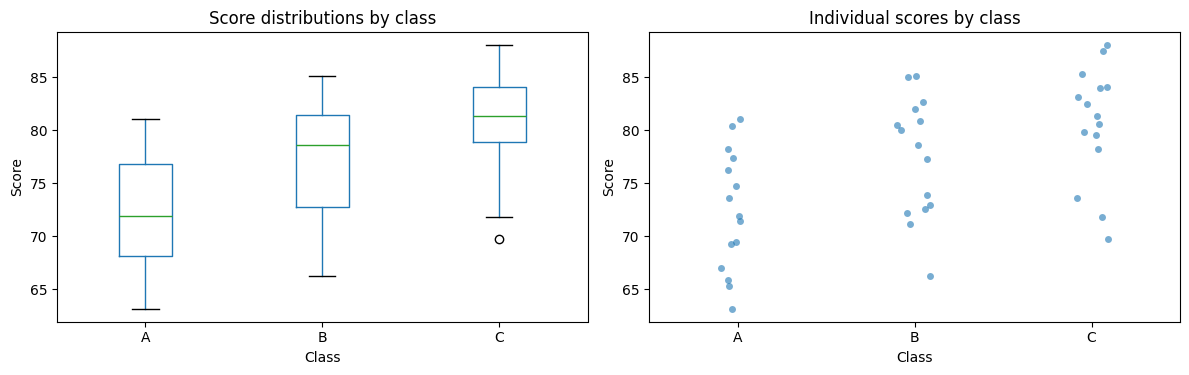

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualise the three groups.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Box plot.
scores.boxplot(column='score', by='class_label', ax=axes[0], grid=False)
axes[0].set_title('Score distributions by class')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Score')
fig.suptitle('')

# Strip plot.
sns.stripplot(data=scores, x='class_label', y='score', ax=axes[1],
              jitter=True, alpha=0.6)
axes[1].set_title('Individual scores by class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Score')

fig.tight_layout()
plt.show()


#### Approach 1: A direct ANOVA with SciPy

**Function and parameters:** `stats.f_oneway(class_A, class_B, class_C)`.

- `class_A`, `class_B`, and `class_C` are the three independent score samples, supplied as separate arrays. Changing their order does not change the ANOVA result.
- The default performs standard one-way ANOVA, assuming equal population variances.
- The function returns the F statistic and p-value, stored in `f_stat` and `p_value`.

[Function reference: SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html)


In [37]:
# Approach 1: SciPy f_oneway.
from scipy import stats

f_stat, p_value = stats.f_oneway(class_A, class_B, class_C)

print('SciPy one-way ANOVA:')
print(f'  F statistic: {f_stat:.4f}')
print(f'  p-value:     {p_value:.4f}')


SciPy one-way ANOVA:
  F statistic: 8.4369
  p-value:     0.0008


**Reading the SciPy output:**

- **F statistic ≈ 8.4369:** the between-group mean square is about 8.44 times the within-group mean square.
- **p-value ≈ 0.0008:** if all three population means were equal and the ANOVA assumptions held, the probability of an F statistic at least this large would be about 0.08%.

Since p < 0.05, we reject H₀: there is evidence that at least one population mean differs. ANOVA does not identify which classes differ; that requires post-hoc comparisons.


#### Approach 2: A regression model with statsmodels

**Function and parameters:** `smf.ols('score ~ C(class_label)', data=scores).fit()`, followed by `sm.stats.anova_lm(model, typ=2)`.

- `scores` has one row per student: `score` contains the outcome and `class_label` identifies A, B, or C.
- In the formula, `~` separates the outcome from the predictor. `C(class_label)` treats class labels as categories; Class A is the reference here.
- `data=scores` supplies the DataFrame. `.fit()` estimates the model, including an intercept by default.
- `anova_lm(model, typ=2)` produces a Type II ANOVA table from the fitted model. With this single factor, it tests whether all three population means are equal.
- The result is stored in `anova_table`.

[Formula reference](https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html) · [ANOVA table reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.anova.anova_lm.html)


In [38]:
# Approach 2: statsmodels OLS + ANOVA table.
import statsmodels.formula.api as smf
import statsmodels.api as sm

model = smf.ols('score ~ C(class_label)', data=scores).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

print('statsmodels ANOVA table:')
display(anova_table.round(4))


statsmodels ANOVA table:


,sum_sq,df,F,PR(>F)
C(class_label),520.356,2.0,8.4369,0.0008
Residual,1295.204,42.0,NaN,NaN


**Reading the statsmodels output:**

| Column | Meaning |
|--------|---------|
| `sum_sq` | Sum of squares: variation attributed to the factor or residuals |
| `df` | Degrees of freedom |
| `F` | Ratio of between-group to within-group mean squares |
| `PR(>F)` | p-value for the factor's F test |

- **`C(class_label)` row:** between-group sum of squares = **520.356**, with **df = 3 − 1 = 2**. Read this row for the overall class comparison.
- **`Residual` row:** within-group sum of squares = **1295.204**, with **df = 45 − 3 = 42**. This is the unexplained variation within classes; its F and p-value are not applicable (`NaN`).
- **F ≈ 8.4369** is calculated as `(520.356 / 2) / (1295.204 / 42)`. 
- **PR(>F)**: **p ≈ 0.0008** leads to the same rejection of H₀ as SciPy.

This table tests the overall class effect, rather than displaying individual regression coefficients. It implements the same standard one-way ANOVA as SciPy.


#### Approach 3: A results table with Pingouin

**Function and parameters:** `pg.anova(data=scores, dv='score', between='class_label', detailed=True)`.

- `data=scores` supplies the DataFrame.
- `dv='score'` names the dependent variable: student score.
- `between='class_label'` names the factor defining the independent groups. One factor gives a one-way ANOVA.
- `detailed=True` includes sums of squares, degrees of freedom, mean squares, and a within-group row.
- The default effect size is partial eta-squared (`np2`), which equals eta-squared (η²) for this one-way ANOVA.
- The returned DataFrame is stored in `aov`; `display(aov.round(4))` displays it rounded to four decimal places.

[Function reference: Pingouin](https://pingouin-stats.org/generated/pingouin.anova.html)


In [39]:
# Approach 3: Pingouin ANOVA.
import pingouin as pg

aov = pg.anova(data=scores, dv='score', between='class_label', detailed=True)

print('Pingouin ANOVA:')
display(aov.round(4))


Pingouin ANOVA:


,Source,SS,DF,MS,F,p_unc,np2
0,class_label,520.356,2,260.1780,8.4369,0.0008,0.2866
1,Within,1295.204,42,30.8382,NaN,NaN,NaN


**Reading the Pingouin output:**

| Column | Meaning |
|--------|---------|
| `Source` | Source of variation: `class_label` (between groups) or `Within` |
| `SS` | Sum of squares |
| `DF` | Degrees of freedom |
| `MS` | Mean square: `SS / DF` |
| `F` | Between-group `MS` divided by within-group `MS` |
| `p_unc` | Uncorrected p-value for the overall ANOVA test |
| `np2` | Partial eta-squared; equals η² in this one-way example |

The **`class_label` row** has **MS = 260.1780**, while the **`Within` row** has **MS ≈ 30.8382**. Their ratio gives **F ≈ 8.4369**, with **p ≈ 0.0008**, matching SciPy and statsmodels. F, p-value, and effect size are not applicable to the `Within` row (`NaN`).

**`np2` ≈ 0.2866:** class membership accounts for about **28.7% of the observed total variation** in scores. This describes the effect magnitude; the p-value provides the test of equal population means. The next subsection explains η² in more detail.


#### Effect size: η² (eta-squared)

The p-value tells us whether the group differences are statistically significant. The **effect size** tells us how large those differences are.

**η² (eta-squared)** represents the proportion of total variance explained by the group variable:

$$\eta^2 = \frac{SS_{\text{between}}}{SS_{\text{total}}}$$

| η² | Interpretation |
|----|----------------|
| 0.01 | Small effect |
| 0.06 | Medium effect |
| 0.14 | Large effect |

Pingouin includes η² in the ANOVA output. For SciPy and statsmodels, compute it from the sum of squares.


In [40]:
# Calculate eta-squared from the ANOVA table.
ss_between = anova_table['sum_sq'].iloc[0]
ss_total = anova_table['sum_sq'].sum()
eta_squared = ss_between / ss_total

print(f'η² (eta-squared): {eta_squared:.4f}')
print(f'The grouping variable explains {eta_squared * 100:.1f}% of the total variance in scores.')

η² (eta-squared): 0.2866
The grouping variable explains 28.7% of the total variance in scores.


### 2.4 Post-Hoc Analysis: Which groups differ?

ANOVA tests whether **at least one** group mean differs, but it does not identify **which** groups are different. **Post-hoc comparisons** identify which pairs differ while accounting for multiple comparisons.

Two common post-hoc methods:

| Method | When to use | Variance assumption |
|--------|-------------|--------------------|
| **Tukey's HSD** | Variances are approximately equal across groups | Equal variances |
| **Games-Howell** | Variances differ across groups | Unequal variances |

Three Approaches in Python:

| Package | Tukey HSD: equal variances | Games–Howell: unequal variances |
|---------|---------------------------|--------------------------------|
| `scipy.stats` | `stats.tukey_hsd(...)` | `stats.tukey_hsd(..., equal_var=False)` |
| `statsmodels` | `pairwise_tukeyhsd(..., use_var='equal')` | `pairwise_tukeyhsd(..., use_var='unequal')` |
| `pingouin` | `pg.pairwise_tukey()` | `pg.pairwise_gameshowell()` |

For the similar-variance data in Section 2.3, **Tukey HSD is the main analysis**. Games–Howell is also shown to demonstrate the unequal-variance alternative. Choose the method based on the data conditions, rather than running both to select a smaller p-value. The three libraries are alternative implementations of the same methods.

Use **α = 0.05** for the pairwise decisions. 


#### Approach 1: SciPy

**Function and parameters:** `stats.tukey_hsd(class_A, class_B, class_C)`.

- The three arrays supply the independent groups; their order defines indices **0 = A, 1 = B, 2 = C**.
- The default selects Tukey HSD here; `equal_var=False` selects Games–Howell.
- The result contains pairwise `statistic` and `pvalue` arrays. `confidence_interval(confidence_level=0.95)` provides simultaneous 95% intervals.

[Function reference: SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html)


In [41]:
# SciPy: Tukey HSD.
from scipy import stats

tukey_sp = stats.tukey_hsd(class_A, class_B, class_C)
print('SciPy: Tukey HSD')
print(tukey_sp)


SciPy: Tukey HSD
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -5.060     0.043    -9.986    -0.134
 (0 - 2)     -8.260     0.001   -13.186    -3.334
 (1 - 0)      5.060     0.043     0.134     9.986
 (1 - 2)     -3.200     0.266    -8.126     1.726
 (2 - 0)      8.260     0.001     3.334    13.186
 (2 - 1)      3.200     0.266    -1.726     8.126



In [42]:
# SciPy: Games–Howell.
from scipy import stats

gh_sp = stats.tukey_hsd(class_A, class_B, class_C, equal_var=False)
print('SciPy: Games–Howell')
print(gh_sp)


SciPy: Games–Howell
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -5.060     0.051   -10.142     0.022
 (0 - 2)     -8.260     0.001   -13.255    -3.265
 (1 - 0)      5.060     0.051    -0.022    10.142
 (1 - 2)     -3.200     0.266    -8.175     1.775
 (2 - 0)      8.260     0.001     3.265    13.255
 (2 - 1)      3.200     0.266    -1.775     8.175



**Reading the SciPy output:**

| Field | Meaning |
|-------|---------|
| `Comparison` | Group indices; `(0 - 1)` means A minus B |
| `Statistic` | Mean difference, **not a t or F statistic** |
| `p-value` | Multiplicity-adjusted p-value |
| `Lower CI` / `Upper CI` | Simultaneous confidence limits for the mean difference |

For `(0 - 1)`, the difference is **−5.06**. Tukey gives **p ≈ 0.0430**, with interval **[−9.9864, −0.1336]**, supporting different means. Games–Howell gives **p ≈ 0.0512**, with an interval containing zero.


#### Approach 2: statsmodels

**Function and parameters:** `pairwise_tukeyhsd(endog=scores['score'], groups=scores['class_label'], alpha=0.05, use_var='equal')`.

- `endog` contains all scores, and `groups` supplies each score's class label.
- `alpha=0.05` sets the family-wise significance level and corresponding 95% simultaneous intervals.
- `use_var='equal'` selects Tukey HSD; `use_var='unequal'` selects Games–Howell.
- The returned object contains pairwise differences, adjusted p-values, intervals, and rejection decisions. `display(result.summary())` displays its formatted results table.

[Function reference: statsmodels](https://www.statsmodels.org/stable/generated/statsmodels.stats.multicomp.pairwise_tukeyhsd.html)


In [43]:
# statsmodels: Tukey HSD.
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_sm = pairwise_tukeyhsd(
    endog=scores['score'], groups=scores['class_label'],
    alpha=0.05, use_var='equal'
)
print('statsmodels: Tukey HSD')
display(tukey_sm.summary())


statsmodels: Tukey HSD


group1,group2,meandiff,p-adj,lower,upper,reject
A,B,5.06,0.043,0.1336,9.9864,True
A,C,8.26,0.0006,3.3336,13.1864,True
B,C,3.2,0.2662,-1.7264,8.1264,False


In [44]:
# statsmodels: Games–Howell.
from statsmodels.stats.multicomp import pairwise_tukeyhsd

gh_sm = pairwise_tukeyhsd(
    endog=scores['score'], groups=scores['class_label'],
    alpha=0.05, use_var='unequal'
)
print('statsmodels: Games–Howell')
display(gh_sm.summary())


statsmodels: Games–Howell


group1,group2,meandiff,p-adj,lower,upper,reject
A,B,5.06,0.0512,-0.0223,10.1423,False
A,C,8.26,0.0009,3.2653,13.2547,True
B,C,3.2,0.2659,-1.7753,8.1753,False


**Reading the statsmodels output:**

| Column | Meaning |
|--------|---------|
| `group1` / `group2` | The two classes compared |
| `meandiff` | Mean of **group2 minus group1** |
| `p-adj` | Multiplicity-adjusted p-value |
| `lower` / `upper` | Simultaneous confidence limits |
| `reject` | Whether equal population means are rejected at α = 0.05 |

For A–B, **meandiff = 5.06**, because statsmodels reports B minus A. Tukey gives **p-adj ≈ 0.0430** and **reject = True**; Games–Howell gives **p-adj ≈ 0.0512** and **reject = False**. These agree with SciPy despite the opposite difference direction.

Some versions retain “Tukey HSD” in the displayed table heading for both methods; `use_var='unequal'` determines the Games–Howell calculation.


#### Approach 3: Pingouin

**Functions and parameters:** `pg.pairwise_tukey(data=scores, dv='score', between='class_label')` and `pg.pairwise_gameshowell(...)`.

- `data=scores` supplies the DataFrame; `dv='score'` names the outcome; `between='class_label'` identifies the independent groups.
- The function name selects Tukey HSD or Games–Howell.
- The default `effsize='hedges'` includes Hedges' g, a standardised mean difference with a small-sample correction.
- Both functions return DataFrames. `.round(4)` formats the displayed values; compare their adjusted p-values with α = 0.05.

[Tukey reference](https://pingouin-stats.org/generated/pingouin.pairwise_tukey.html) · [Games–Howell reference](https://pingouin-stats.org/generated/pingouin.pairwise_gameshowell.html)


In [45]:
# Pingouin: Tukey HSD.
import pingouin as pg

tukey = pg.pairwise_tukey(data=scores, dv='score', between='class_label')
print('Pingouin: Tukey HSD')
display(tukey.round(4))


Pingouin: Tukey HSD


,A,B,mean_A,mean_B,diff,se,T,p_tukey,hedges
0,A,B,72.36,77.42,-5.06,2.0277,-2.4954,0.0430,-0.8752
1,A,C,72.36,80.62,-8.26,2.0277,-4.0735,0.0006,-1.4540
2,B,C,77.42,80.62,-3.20,2.0277,-1.5781,0.2662,-0.5654


In [46]:
# Pingouin: Games–Howell.
import pingouin as pg

gh = pg.pairwise_gameshowell(data=scores, dv='score', between='class_label')
print('Pingouin: Games–Howell')
display(gh.round(4))


Pingouin: Games–Howell


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,A,B,72.36,77.42,-5.06,2.0540,-2.4635,27.9985,0.0512,-0.8752
1,A,C,72.36,80.62,-8.26,2.0184,-4.0924,27.9477,0.0009,-1.4540
2,B,C,77.42,80.62,-3.20,2.0106,-1.5915,27.9640,0.2659,-0.5654


**Reading the Pingouin output:**

| Column | Meaning |
|--------|---------|
| `A` / `B` | First / second group labels |
| `mean_A` / `mean_B` | Group means (older versions use `mean(A)` / `mean(B)`) |
| `diff` | Mean of **A minus B** |
| `se` | Standard error of the mean difference |
| `T` | Mean difference divided by its standard error |
| `df` | Pair-specific degrees of freedom; Games–Howell only |
| `p_tukey` / `pval` | Adjusted p-value for Tukey / Games–Howell (older versions use `p-tukey`) |
| `hedges` | Hedges' g; its sign follows the difference direction |

The A–B row has **diff = −5.06**. Tukey's adjusted p-value is **≈ 0.0430**; Games–Howell's is **≈ 0.0512**, matching the other libraries. These tables do not include confidence intervals by default.


**Conclusion for the student-score example:**

| Pair (SciPy indices) | Mean difference (first minus second) | Tukey adjusted p | Significant at α = 0.05? |
|---------------------|--------------------------------------|------------------|--------------------------|
| A–B (0–1) | −5.06 | 0.0430 | Yes |
| A–C (0–2) | −8.26 | 0.0006 | Yes |
| B–C (1–2) | −3.20 | 0.2662 | No |

Using **Tukey HSD**, our selected method for this similar-variance example:

- **A–B (0–1):** The adjusted p-value is **0.0430 < 0.05**, so there is evidence that their population means differ. A's sample mean is **5.06 points lower** than B's.
- **A–C (0–2):** The adjusted p-value is **0.0006 < 0.05**, so there is evidence that their population means differ. A's sample mean is **8.26 points lower** than C's.
- **B–C (1–2):** The adjusted p-value is **0.2662 > 0.05**, so there is insufficient evidence that their population means differ. This does not establish that their population means are equal.

The p-values above are adjusted for multiple comparisons. SciPy, statsmodels, and Pingouin give consistent Tukey HSD results.


## 3. Case Study: Do Mean Tips Differ Across Days?

This case study follows Steps 1–6 of the testing workflow from Session 11: define the question, inspect the data, select a test, and calculate and interpret the result.


### Step 1: Define the question

**Do mean tip amounts differ across the four days (Thursday, Friday, Saturday, Sunday)?**


### Step 2: Identify variables

- **Outcome (dependent variable):** `tip`, numeric, continuous.
- **Grouping (independent variable):** `day`, categorical with 4 levels: Thur, Fri, Sat, Sun.


### Step 3: Inspect the data


In [47]:
# Load the tips dataset.
import seaborn as sns

tips = sns.load_dataset('tips')

print(f'Shape: {tips.shape}')
print(f'Missing values: {tips.isnull().sum().sum()}')
print()
display(tips.head())

Shape: (244, 7)
Missing values: 0



,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [48]:
# Group summary: tip by day.
day_order = ['Thur', 'Fri', 'Sat', 'Sun']
day_summary = (tips.groupby('day')['tip']
               .agg(['count', 'mean', 'std', 'median'])
               .reindex(day_order))

print('Tip summary by day:')
display(day_summary.round(3))

Tip summary by day:


,count,mean,std,median
day,,,,
Thur,62,2.771,1.240,2.305
Fri,19,2.735,1.020,3.000
Sat,87,2.993,1.631,2.750
Sun,76,3.255,1.235,3.150


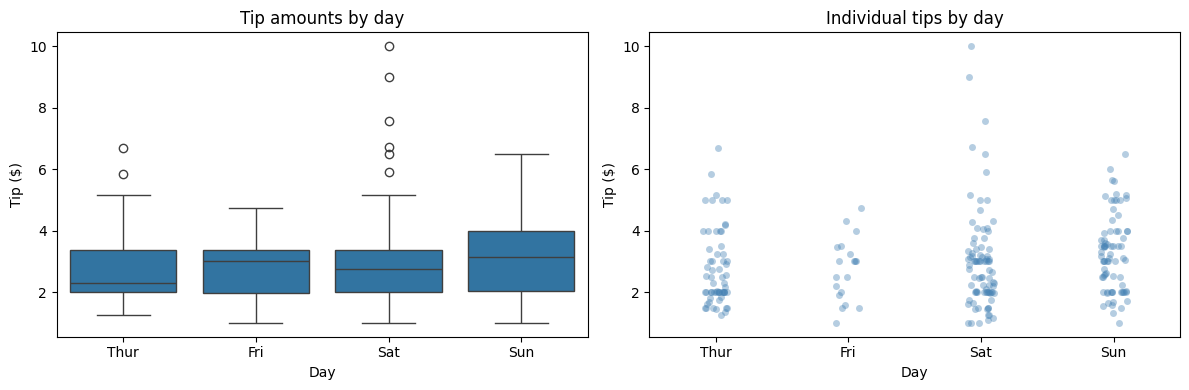

In [49]:
# Visualise tip distributions by day.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Box plot.
sns.boxplot(data=tips, x='day', y='tip', order=day_order, ax=axes[0])
axes[0].set_title('Tip amounts by day')
axes[0].set_xlabel('Day')
axes[0].set_ylabel('Tip ($)')

# Strip plot overlaid on box plot.
sns.stripplot(data=tips, x='day', y='tip', order=day_order, ax=axes[1],
              jitter=True, alpha=0.4, color='steelblue')
axes[1].set_title('Individual tips by day')
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Tip ($)')

fig.tight_layout()
plt.show()

### Step 4: Set hypotheses and significance level

- **H₀:** The mean tip is equal across all four days: μ_Thur = μ_Fri = μ_Sat = μ_Sun
- **H₁:** At least one day has a different mean tip.
- **α = 0.05**


### Step 5: Choose the method

We have one continuous outcome (`tip`) and one categorical grouping variable (`day`) with four levels. This calls for a **one-way ANOVA**.

With group sizes of 62, 19, 87, and 76 for Thursday, Friday, Saturday, and Sunday, respectively, and similar group variability (standard deviations of 1.24, 1.02, 1.63, and 1.24), **standard one-way ANOVA is a reasonable working choice for this example**, assuming independent observations.


### Step 6: Calculate and interpret

Use `scipy.stats.f_oneway()` to perform standard one-way ANOVA, then compare its p-value with α = 0.05. Calculate η² from the group summaries to describe the effect size.


In [50]:
# Main approach: SciPy one-way ANOVA.
from scipy import stats

day_groups = [tips.loc[tips['day'] == day, 'tip'] for day in day_order]
f_stat, p_value = stats.f_oneway(*day_groups)
df_between = len(day_groups) - 1
df_within = sum(len(group) for group in day_groups) - len(day_groups)

# Effect size does not depend on the optional approaches below.
grand_mean = tips['tip'].mean()
ss_between = sum(len(group) * (group.mean() - grand_mean)**2 for group in day_groups)
ss_total = ((tips['tip'] - grand_mean)**2).sum()
eta_sq = ss_between / ss_total

print('SciPy one-way ANOVA:')
print(f'  F({df_between}, {df_within}) = {f_stat:.4f}')
print(f'  p-value = {p_value:.4f}')
print(f'  η² = {eta_sq:.4f}')

SciPy one-way ANOVA:
  F(3, 240) = 1.6724
  p-value = 0.1736
  η² = 0.0205


**Result and conclusion:**

- **Group means:** Mean tips are approximately $2.77 on Thursday (n = 62), $2.73 on Friday (n = 19), $2.99 on Saturday (n = 87), and $3.26 on Sunday (n = 76).
- **Test result:** Standard one-way ANOVA gives **F(3, 240) ≈ 1.6724** and **p ≈ 0.1736**. F compares variation between the group means with variation within the groups.
- **Decision:** Since **p > 0.05**, **we fail to reject H₀**.
- **Conclusion:** **There is insufficient evidence that mean tip amounts differ across the four days.** This does not prove that their population means are equal.
- **Effect size:** **η² ≈ 0.0205**, so differences between days account for about **2.0% of the observed total variation** in tip amounts.
- **Post-hoc analysis:** Because the overall ANOVA is not significant, we do not proceed to post-hoc comparisons in this workflow.

These observational data do not establish a causal effect of day on tips; total bill and party size are not controlled.


#### Other approaches (optional)

The SciPy calculation and decision above complete Step 6. The following code cells demonstrate alternative interfaces; **choose one approach for an analysis, rather than running all three each time**. You may skip these examples and continue to Section 4.

**statsmodels:** Fit `tip ~ C(day)`, then use `sm.stats.anova_lm(..., typ=2)` to produce the ANOVA table. Read `F` and `PR(>F)` in the `C(day)` row.


In [51]:
# Optional approach: statsmodels OLS + ANOVA table.
import statsmodels.formula.api as smf
import statsmodels.api as sm

model = smf.ols('tip ~ C(day)', data=tips).fit()
anova_tbl = sm.stats.anova_lm(model, typ=2)
display(anova_tbl.round(4))

,sum_sq,df,F,PR(>F)
C(day),9.5259,3.0,1.6724,0.1736
Residual,455.6866,240.0,NaN,NaN


**Pingouin:** Use `pg.anova()` with `dv='tip'`, `between='day'`, and `detailed=True`. Read `F`, `p_unc`, and `np2` in the `day` row; for this one-way ANOVA, `np2` equals η². Both optional approaches give the same standard ANOVA result as SciPy.


In [52]:
# Optional approach: Pingouin.
import pingouin as pg

aov = pg.anova(data=tips, dv='tip', between='day', detailed=True)
display(aov.round(4))

,Source,SS,DF,MS,F,p_unc,np2
0,day,9.5259,3,3.1753,1.6724,0.1736,0.0205
1,Within,455.6866,240,1.8987,NaN,NaN,NaN


## 4. Exercise: ANOVA

Apply the ANOVA workflow to the `tips` dataset before moving on to Chi-square tests. Use one calculation approach and interpret the result.


**Do mean total bills differ by day?**

Use `total_bill` as the outcome and `day` as the grouping variable.

1. Inspect the data: group sizes, means, standard deviations, box plots.
2. Set hypotheses and α.
3. Check assumptions (normality, Levene's test).
4. Run ANOVA using one approach; the other interfaces are optional.
5. If significant, run post-hoc analysis (Tukey HSD or Games-Howell).
6. Report F, p, η², and post-hoc results.


In [53]:
# Exercise 1: your analysis here.

## 5. Chi-Square Test of Independence


### 5.1 When to use the Chi-Square test

The t-test and ANOVA compare **means of a continuous variable** across groups. But what if both variables are **categorical**?

For example:

| Question | Variables | Test |
|----------|-----------|------|
| Do male and female customers leave different mean tips? | Categorical (sex) vs Continuous (tip) | t-test |
| Do mean tips differ across four days? | Categorical (day) vs Continuous (tip) | ANOVA |
| Is smoking status related to meal time? | Categorical (smoker) vs Categorical (time) | **Chi-square** |

The **Chi-square test of independence** determines whether there is a statistically significant **association** between two categorical variables.


### 5.2 Chi-Square in Python: Two Approaches

This section introduces two approaches to testing the association between two categorical variables: a direct chi-square test with `scipy` and a chi-square results table using `pingouin`. **One approach is sufficient for an analysis.**

| Package | Function | Key feature |
|---------|----------|-------------|
| `scipy.stats` | `chi2_contingency()` | Returns χ², p-value, degrees of freedom, and expected counts |
| `pingouin` | `chi2_independence()` | Results table with several test variants and Cramér's V |

#### Quick demonstration with simulated training outcomes

Two independent groups of 50 students use training methods A and B. The outcome is categorical: Pass or Fail.

| Training method | Pass | Fail | Total |
|-----------------|-----:|-----:|------:|
| A | 30 | 20 | 50 |
| B | 20 | 30 | 50 |
| Total | 50 | 50 | 100 |

**H₀:** Training method and outcome are independent. **H₁:** They are associated. Use **α = 0.05**.


In [54]:
# Simulated categorical data: one row per student.
import numpy as np
import pandas as pd

training = pd.DataFrame({
    'method': ['A'] * 50 + ['B'] * 50,
    'outcome': ['Pass'] * 30 + ['Fail'] * 20 + ['Pass'] * 20 + ['Fail'] * 30
})
observed_demo = pd.crosstab(training['method'], training['outcome']).reindex(
    index=['A', 'B'], columns=['Pass', 'Fail']
)
print('Observed frequencies (without margins):')
display(observed_demo)

Observed frequencies (without margins):


outcome,Pass,Fail
method,,
A,30,20
B,20,30


#### Approach 1: A direct Chi-Square test with SciPy

**Function and parameters:** `stats.chi2_contingency(observed_demo, correction=False)`.

- `observed_demo` contains the 2×2 observed counts; exclude totals and percentages.
- `correction=False` selects the uncorrected Pearson calculation. The default `correction=True` applies Yates' correction when df = 1 and can give a different p-value.
- The four returned values are the χ² statistic, p-value, degrees of freedom, and expected counts under independence.

[Function reference: SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)


In [55]:
# Approach 1: SciPy.
from scipy import stats

chi2_demo, p_demo, dof_demo, expected_demo = stats.chi2_contingency(
    observed_demo, correction=False
)
print('SciPy Pearson Chi-square test:')
print(f'  χ² = {chi2_demo:.4f}, df = {dof_demo}, p = {p_demo:.4f}')
print('Expected frequencies under H₀:')
display(pd.DataFrame(expected_demo, index=observed_demo.index,
                     columns=observed_demo.columns).round(2))

SciPy Pearson Chi-square test:
  χ² = 4.0000, df = 1, p = 0.0455
Expected frequencies under H₀:


outcome,Pass,Fail
method,,
A,25.0,25.0
B,25.0,25.0


**Reading the SciPy output:**

- **Expected counts = 25 in each cell:** under independence, each method would have 25 passes and 25 fails given these margins. All expected counts exceed 5.
- **χ² = 4.0000:** this summarises the discrepancy between the observed and expected counts.
- **df = (2 − 1) × (2 − 1) = 1** determines the reference χ² distribution.
- **p ≈ 0.0455 < 0.05:** we reject H₀; there is evidence of an association between training method and outcome.

The observed pass rates are **60% for A** and **40% for B**. The test detects an association; it does not by itself establish that the training method causes the difference.


#### Approach 2: A results table with Pingouin

**Function and parameters:** `pg.chi2_independence(data=training, x='method', y='outcome', correction=False)`.

- `data=training` supplies individual records, rather than an aggregated count table.
- `x` and `y` name the two categorical variables.
- `correction=False` matches the uncorrected Pearson calculation above.
- The function returns expected counts, observed counts, and a table of test variants. Select the **`pearson` row** to compare with the direct SciPy test.

[Function reference: Pingouin](https://pingouin-stats.org/generated/pingouin.chi2_independence.html)


In [56]:
# Approach 2: Pingouin; display only the selected Pearson test.
import pingouin as pg

expected_pg_demo, observed_pg_demo, chi2_pg_demo = pg.chi2_independence(
    data=training, x='method', y='outcome', correction=False
)
pearson_demo = chi2_pg_demo.loc[chi2_pg_demo['test'] == 'pearson']
display(pearson_demo.round(4))

,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,4.0,1.0,0.0455,0.2,0.516


**Reading the Pingouin output:**

| Column | Meaning |
|--------|---------|
| `test` | Test variant; `pearson` is the selected test |
| `lambda` | Power-divergence parameter; 1 selects Pearson's χ² |
| `chi2` | χ² statistic |
| `dof` | Degrees of freedom |
| `pval` | p-value for independence |
| `cramer` | Cramér's V effect size |
| `power` | Estimated power under the observed effect; not the significance decision |

The Pearson row gives **χ² = 4.0000**, **df = 1**, and **p ≈ 0.0455**, matching SciPy. **Cramér's V = 0.20** describes the magnitude of association. The other returned test variants are alternatives, rather than additional tests required for this analysis.


#### Effect size: Cramér's V

Cramér's V describes the strength of association between two categorical variables:

$$V = \sqrt{\frac{\chi^2}{n \times (\min(r, c) - 1)}}$$

Here χ² is the **uncorrected Pearson statistic**, n is the total sample size, and r and c are the numbers of rows and columns. V ranges from 0 to 1; larger values indicate stronger association, without identifying a direction or establishing causation.

For a **2×2 table**, common rough reference values are:

| Cramér's V | Rough interpretation |
|------------|----------------------|
| 0.10 | Small association |
| 0.30 | Medium association |
| 0.50 | Large association |

These labels depend on context and table dimensions. Pingouin supplies `cramer`; with SciPy, calculate V from the same uncorrected statistic.


In [57]:
# Cramér's V for the simulated example.
n_demo = observed_demo.to_numpy().sum()
min_dim_demo = min(observed_demo.shape) - 1
cramers_v_demo = np.sqrt(chi2_demo / (n_demo * min_dim_demo))
print(f"Cramér's V = {cramers_v_demo:.4f}")

Cramér's V = 0.2000


**Conclusion for the simulated example:** There is evidence that training method and outcome are associated at α = 0.05 (χ²(1) = 4.00, p ≈ 0.0455). Cramér's V = 0.20 indicates a small association using the rough 2×2 reference values above. SciPy and Pingouin give the same uncorrected Pearson result.


## 6. Case Study: Is Smoking Associated with Meal Time?

This case study follows Steps 1–6 of the testing workflow. Use SciPy as the main approach; the Pingouin alternative is optional.


### Step 1: Define the question

**Is there an association between smoking status and meal time (Lunch vs Dinner) in the tips dataset?**


### Step 2: Identify variables

- **Variable 1:** `smoker` (categorical: Yes, No)
- **Variable 2:** `time` (categorical: Lunch, Dinner)
- Both variables are categorical, so we use the Chi-square test of independence.


### Step 3: Inspect the data


In [58]:
# Contingency table.
ct = pd.crosstab(tips['smoker'], tips['time'], margins=True)
print('Observed frequencies:')
display(ct)
print()

# Proportions.
ct_prop = pd.crosstab(tips['smoker'], tips['time'], normalize='columns')
print('Column proportions:')
display(ct_prop.round(3))

Observed frequencies:


time,Lunch,Dinner,All
smoker,,,
Yes,23,70,93
No,45,106,151
All,68,176,244



Column proportions:


time,Lunch,Dinner
smoker,,
Yes,0.338,0.398
No,0.662,0.602


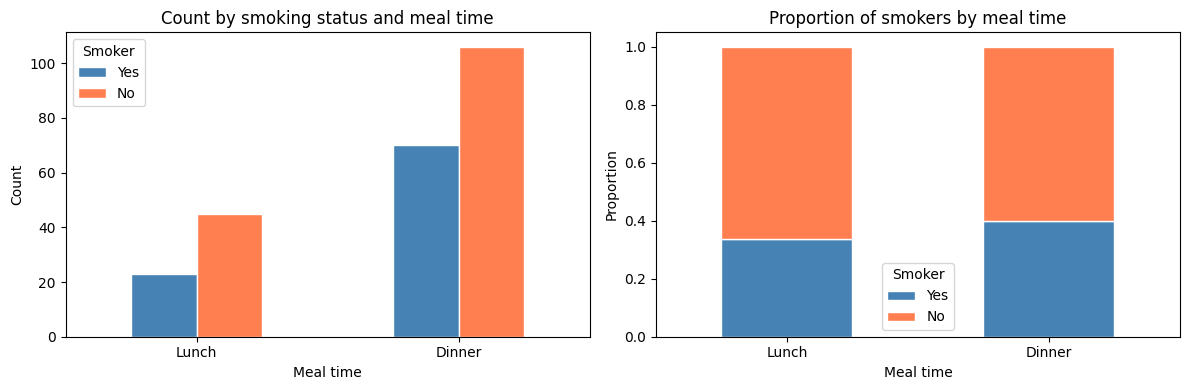

In [59]:
# Stacked bar chart.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Grouped bar chart of counts.
pd.crosstab(tips['time'], tips['smoker']).plot(kind='bar', ax=axes[0], rot=0,
    color=['steelblue', 'coral'], edgecolor='white')
axes[0].set_title('Count by smoking status and meal time')
axes[0].set_xlabel('Meal time')
axes[0].set_ylabel('Count')
axes[0].legend(title='Smoker')

# Proportion bar chart.
ct_prop.T.plot(kind='bar', stacked=True, ax=axes[1], rot=0,
    color=['steelblue', 'coral'], edgecolor='white')
axes[1].set_title('Proportion of smokers by meal time')
axes[1].set_xlabel('Meal time')
axes[1].set_ylabel('Proportion')
axes[1].legend(title='Smoker')

fig.tight_layout()
plt.show()

### Step 4: Set hypotheses and significance level

- **H₀:** Smoking status and meal time are independent (no association).
- **H₁:** There is an association between smoking status and meal time.
- **α = 0.05**


### Step 5: Choose the method

Both `smoker` and `time` are categorical, so use the **Chi-square test of independence**, assuming the bills are independent observations.


### Step 6: Calculate and interpret

Use `stats.chi2_contingency(..., correction=False)` as in Section 5, then compare the p-value with α = 0.05. Calculate Cramér's V from the same Pearson statistic. 


In [60]:
# Main approach: SciPy Pearson Chi-square test.
from scipy import stats

# Test counts only: exclude the table margins shown in Step 3.
observed_cs = pd.crosstab(tips['smoker'], tips['time'])
chi2_cs, p_cs, dof_cs, expected_cs = stats.chi2_contingency(
    observed_cs, correction=False
)
n_cs = observed_cs.to_numpy().sum()
cramers_v_cs = np.sqrt(chi2_cs / (n_cs * (min(observed_cs.shape) - 1)))

print('SciPy Pearson Chi-square test:')
print(f'  χ²({dof_cs}) = {chi2_cs:.4f}')
print(f'  p-value = {p_cs:.4f}')
print(f"  Cramér's V = {cramers_v_cs:.4f}")
print('Expected frequencies under H₀:')
display(pd.DataFrame(expected_cs, index=observed_cs.index,
                     columns=observed_cs.columns).round(2))

SciPy Pearson Chi-square test:
  χ²(1) = 0.7360
  p-value = 0.3910
  Cramér's V = 0.0549
Expected frequencies under H₀:


time,Lunch,Dinner
smoker,,
Yes,25.92,67.08
No,42.08,108.92


**Result and conclusion:**

- **Observed proportions:** Smoking bills represent **23/68 ≈ 33.8%** of Lunch bills and **70/176 ≈ 39.8%** of Dinner bills, a difference of about **6.0 percentage points**.
- **Test result:** The uncorrected Pearson test gives **χ²(1) ≈ 0.7360** and **p ≈ 0.3910**. The statistic measures the discrepancy between observed counts and counts expected under independence.
- **Decision:** Since **p > 0.05**, **we fail to reject H₀**.
- **Conclusion:** **There is insufficient evidence of an association between smoking status and meal time.** This does not prove that the variables are independent.
- **Effect size:** **Cramér's V ≈ 0.0549**, below the rough 0.10 reference for a small association in a 2×2 table, indicating a weak observed association.

These are observational records from one restaurant; the analysis does not establish causation or guarantee that the result generalises to other restaurants.


#### Other approach (optional)

The SciPy calculation and decision above complete Step 6. Pingouin provides an alternative interface to the same uncorrected Pearson test. **Choose one approach for an analysis; you do not need to run both.** You may skip this example and continue to Section 7.


**Pingouin:** Supply the individual records with `x='smoker'`, `y='time'`, and `correction=False`. Select the `pearson` row; its `chi2`, `pval`, and `cramer` reproduce the SciPy statistic, p-value, and Cramér's V.


In [61]:
# Optional approach: Pingouin.
import pingouin as pg

expected_pg_cs, observed_pg_cs, chi2_pg_cs = pg.chi2_independence(
    data=tips, x='smoker', y='time', correction=False
)
pearson_cs = chi2_pg_cs.loc[chi2_pg_cs['test'] == 'pearson']
display(pearson_cs.round(4))

,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.0,0.736,1.0,0.391,0.0549,0.1376


## 7. Choosing the Right Test

Session 11 and Session 12 together cover three types of statistical tests. The choice depends on two factors:

1. **What type of variables do you have?** (continuous outcome vs categorical outcome)
2. **How many groups are you comparing?** (2 groups vs 3 or more)


### Decision flowchart

```text
What do you want to compare?
    │
    ├── Means of a continuous variable (group comparison)
    │       │
    │       ├── 2 groups → t-test (Session 11)
    │       │
    │       └── 3+ groups → One-way ANOVA (Session 12)
    │               └── Significant → Post-hoc (Tukey HSD)
    │
    └── Association between categorical variables
            │
            └── Chi-square test of independence (Session 12)
```


## 8. Exercise: Chi-Square

Complete the following exercise using the `tips` dataset. Follow Steps 1–6 of the testing workflow and interpret the result.


**Is there an association between day of the week and meal time (Lunch vs Dinner)?**

Use `day` and `time` as the two categorical variables.

1. Build a contingency table and visualise proportions.
2. Set hypotheses and α.
3. Check expected frequencies.
4. Run the Pearson Chi-square test using one approach; the other interfaces are optional.
5. Report χ², p, Cramér's V, and interpretation.


In [62]:
# Exercise 2: your analysis here.